In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.svm import SVC

RANDOM_STATE = 42
TEST_SIZE = 0.3

In [2]:
def load_data(path):
    df = pd.read_csv(path, sep=None, engine="python")
    X = df.iloc[:, :-1].to_numpy(dtype=float)
    y = df.iloc[:, -1].to_numpy()
    return X, y


def compute_gamma_scale(X):
    return 1.0 / (X.shape[1] * X.var())


def manual_decision_function(clf, x):
    sv = clf.support_vectors_
    dual_coef = clf.dual_coef_[0]
    intercept = clf.intercept_[0]

    if clf.kernel == "rbf":
        k = np.exp(-clf.gamma * np.sum((x[:, None, :] - sv[None, :, :]) ** 2, axis=2))
    elif clf.kernel == "poly":
        k = (clf.gamma * x @ sv.T + clf.coef0) ** clf.degree
    elif clf.kernel == "linear":
        k = x @ sv.T
    else:
        raise ValueError(f"Неподдерживаемое ядро: {clf.kernel}")

    return k @ dual_coef + intercept


def manual_predict(clf, x):
    decision_values = manual_decision_function(clf, x)
    return np.where(decision_values >= 0, clf.classes_[1], clf.classes_[0])


def errors_by_class(y_true, y_pred):
    result = {}

    for c in np.unique(y_true):
        idx = y_true == c
        result[int(c)] = int(np.sum(y_pred[idx] != y_true[idx]))

    return result


def expand_error_columns(results_df):
    df = results_df.copy()

    if len(df) == 0:
        return df

    class_labels = sorted(df["train_errors_by_class"].iloc[0].keys())

    for c in class_labels:
        df[f"train_errors_class_{c}"] = df["train_errors_by_class"].apply(lambda d: d[c])
        df[f"test_errors_class_{c}"] = df["test_errors_by_class"].apply(lambda d: d[c])

    return df

In [3]:
def plot_svm_result(clf, X_train, y_train, X_test, y_test, title, ax=None, show=True):
    y_train_pred = clf.predict(X_train)
    y_test_pred = clf.predict(X_test)

    classes = np.unique(y_train)
    colors = {classes[0]: "tab:blue", classes[1]: "tab:orange"}

    standalone = ax is None
    if standalone:
        fig, ax = plt.subplots(figsize=(8, 6))

    for c in classes:
        idx = y_train == c
        ax.scatter(
            X_train[idx, 0], X_train[idx, 1],
            c=colors[c], s=28, alpha=0.55,
            label=f"обучающие, класс {c}"
        )

    wrong_train = y_train_pred != y_train
    ax.scatter(
        X_train[wrong_train, 0], X_train[wrong_train, 1],
        facecolors="none", edgecolors="red",
        s=110, linewidths=1.8,
        label="обучающие, ошибки"
    )

    for c in classes:
        idx = (y_test == c) & (y_test_pred == c)
        ax.scatter(
            X_test[idx, 0], X_test[idx, 1],
            marker="s", c=colors[c], s=45, edgecolors="black", linewidths=0.7,
            label=f"тестовые, верно, класс {c}"
        )

    wrong_test = y_test_pred != y_test
    ax.scatter(
        X_test[wrong_test, 0], X_test[wrong_test, 1],
        marker="X", c="red", s=85, edgecolors="black", linewidths=0.7,
        label="тестовые, ошибки"
    )

    ax.scatter(
        clf.support_vectors_[:, 0], clf.support_vectors_[:, 1],
        s=150, facecolors="none", edgecolors="green",
        linewidths=1.8, label="опорные векторы"
    )

    ax.set_title(title, fontsize=10)
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7, loc="best")

    if standalone:
        plt.tight_layout()
        if show:
            plt.show()

    return ax


def make_title(kernel, gamma_value, C, coef0, result):
    return (
        f"{kernel}, gamma={gamma_value:.4g}, C={C}, coef0={coef0}\n"
        f"опорные векторы: {result['n_support_vectors']}, "
        f"ошибки train: {result['train_errors_total']}, "
        f"ошибки test: {result['test_errors_total']}"
    )


def run_experiment(X, y, kernel, gamma_value, C, coef0=0.0, degree=3, plot=False, ax=None):
    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=TEST_SIZE,
        random_state=RANDOM_STATE,
        stratify=y
    )

    clf = SVC(
        kernel=kernel,
        C=C,
        gamma=gamma_value,
        degree=degree,
        coef0=coef0,
        random_state=RANDOM_STATE
    )
    clf.fit(X_train, y_train)

    y_train_pred = clf.predict(X_train)
    y_test_pred = clf.predict(X_test)

    train_errors = errors_by_class(y_train, y_train_pred)
    test_errors = errors_by_class(y_test, y_test_pred)

    max_diff = 0.0
    n_check = min(10, X_test.shape[0])

    for j in range(n_check):
        manual_value = manual_decision_function(clf, X_test[j:j + 1, :])[0]
        sklearn_value = clf.decision_function(X_test[j:j + 1, :])[0]
        max_diff = max(max_diff, abs(manual_value - sklearn_value))

    result = {
        "kernel": kernel,
        "gamma": gamma_value,
        "C": C,
        "coef0": coef0,
        "degree": degree,
        "n_support_vectors": int(clf.n_support_.sum()),
        "train_errors_total": int(np.sum(y_train_pred != y_train)),
        "test_errors_total": int(np.sum(y_test_pred != y_test)),
        "train_errors_by_class": train_errors,
        "test_errors_by_class": test_errors,
        "manual_vs_sklearn_max_abs_diff": max_diff
    }

    if plot:
        title = make_title(kernel, gamma_value, C, coef0, result)
        plot_svm_result(clf, X_train, y_train, X_test, y_test, title=title, ax=ax)

    return clf, result

In [4]:
X1, y1 = load_data("1.csv")

print("X1 shape:", X1.shape)
print("Classes:", np.unique(y1))

gamma_scale_1 = compute_gamma_scale(X1)
print("gamma scale for Nonlin_ker_1 =", gamma_scale_1)

gamma_grid_1 = [
    gamma_scale_1,
    gamma_scale_1 / 10,
    gamma_scale_1 * 10
]

gamma_grid_1

X1 shape: (149, 2)
Classes: [-1  1]
gamma scale for Nonlin_ker_1 = 0.115060256052199


[np.float64(0.115060256052199),
 np.float64(0.0115060256052199),
 np.float64(1.1506025605219898)]

In [5]:
results_1 = []

for kernel in ["rbf", "poly"]:
    for gamma_value in gamma_grid_1:
        for C in [0.01, 1, 1000]:
            _, result = run_experiment(
                X1, y1,
                kernel=kernel,
                gamma_value=gamma_value,
                C=C,
                coef0=0.0,
                plot=False
            )
            results_1.append(result)

results_1_df = expand_error_columns(pd.DataFrame(results_1))
results_1_df

,kernel,gamma,C,coef0,degree,n_support_vectors,train_errors_total,test_errors_total,train_errors_by_class,test_errors_by_class,manual_vs_sklearn_max_abs_diff,train_errors_class_-1,test_errors_class_-1,train_errors_class_1,test_errors_class_1
0,rbf,0.115060,0.01,0.0,3,92,46,20,"{-1: 0, 1: 46}","{-1: 0, 1: 20}",2.220446e-16,0,0,46,20
1,rbf,0.115060,1.00,0.0,3,65,7,3,"{-1: 7, 1: 0}","{-1: 3, 1: 0}",5.773160e-15,7,3,0,0
2,rbf,0.115060,1000.00,0.0,3,9,0,3,"{-1: 0, 1: 0}","{-1: 0, 1: 3}",2.415845e-13,0,0,0,3
3,rbf,0.011506,0.01,0.0,3,93,46,20,"{-1: 0, 1: 46}","{-1: 0, 1: 20}",2.220446e-16,0,0,46,20
4,rbf,0.011506,1.00,0.0,3,93,46,20,"{-1: 0, 1: 46}","{-1: 0, 1: 20}",1.931788e-14,0,0,46,20
5,rbf,0.011506,1000.00,0.0,3,28,1,1,"{-1: 1, 1: 0}","{-1: 0, 1: 1}",2.671641e-12,1,0,0,1
6,rbf,1.150603,0.01,0.0,3,96,46,20,"{-1: 0, 1: 46}","{-1: 0, 1: 20}",1.110223e-16,0,0,46,20
7,rbf,1.150603,1.00,0.0,3,46,1,4,"{-1: 0, 1: 1}","{-1: 0, 1: 4}",9.992007e-16,0,0,1,4
8,rbf,1.150603,1000.00,0.0,3,16,0,3,"{-1: 0, 1: 0}","{-1: 1, 1: 2}",1.243450e-14,0,1,0,2
9,poly,0.115060,0.01,0.0,3,93,46,20,"{-1: 0, 1: 46}","{-1: 0, 1: 20}",2.553513e-15,0,0,46,20


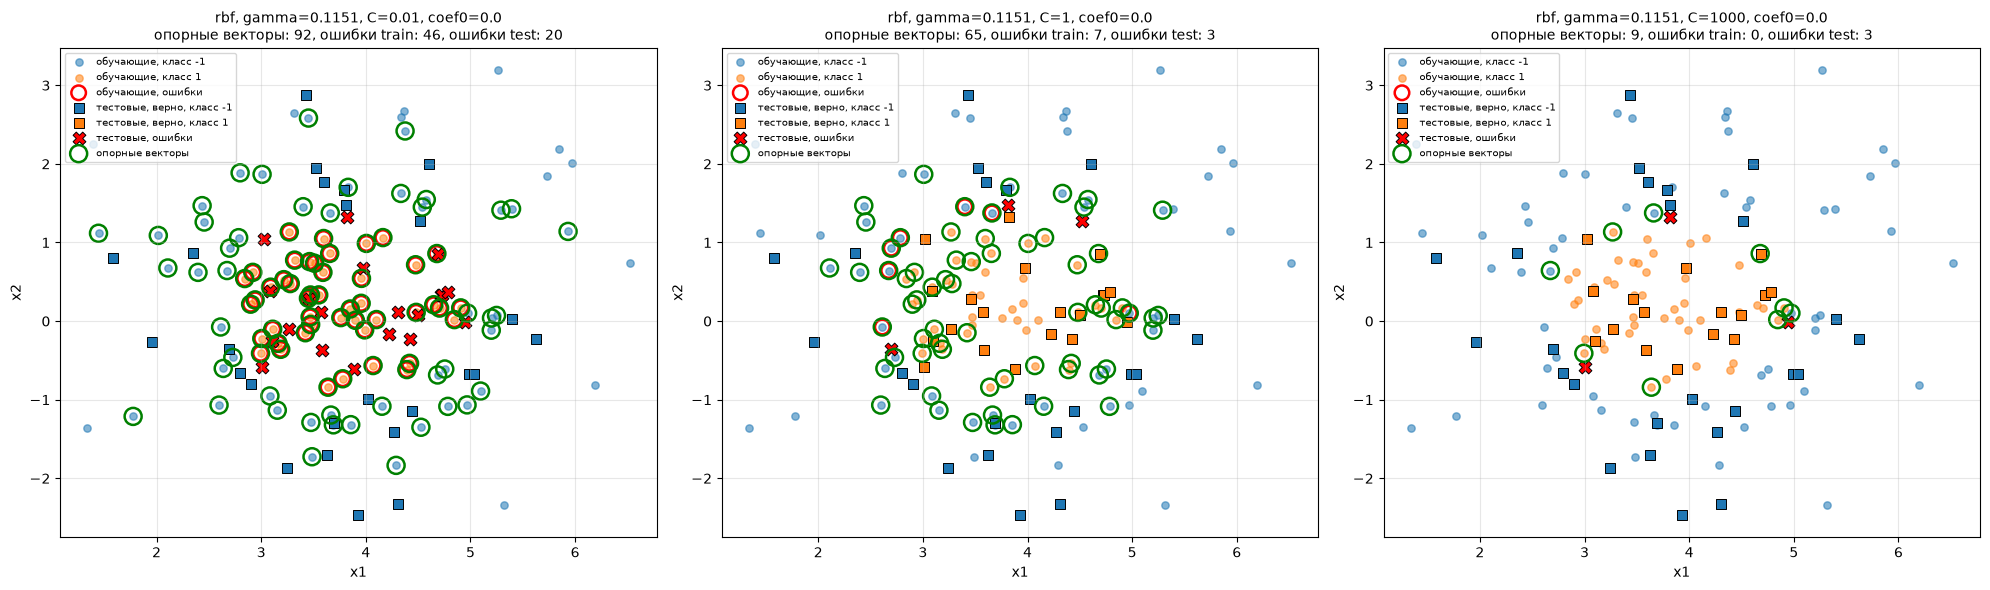

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for ax, C_value in zip(axes, [0.01, 1, 1000]):
    _, result = run_experiment(
        X1, y1,
        kernel="rbf",
        gamma_value=gamma_scale_1,
        C=C_value,
        coef0=0.0,
        plot=True,
        ax=ax
    )

plt.tight_layout()
plt.show()

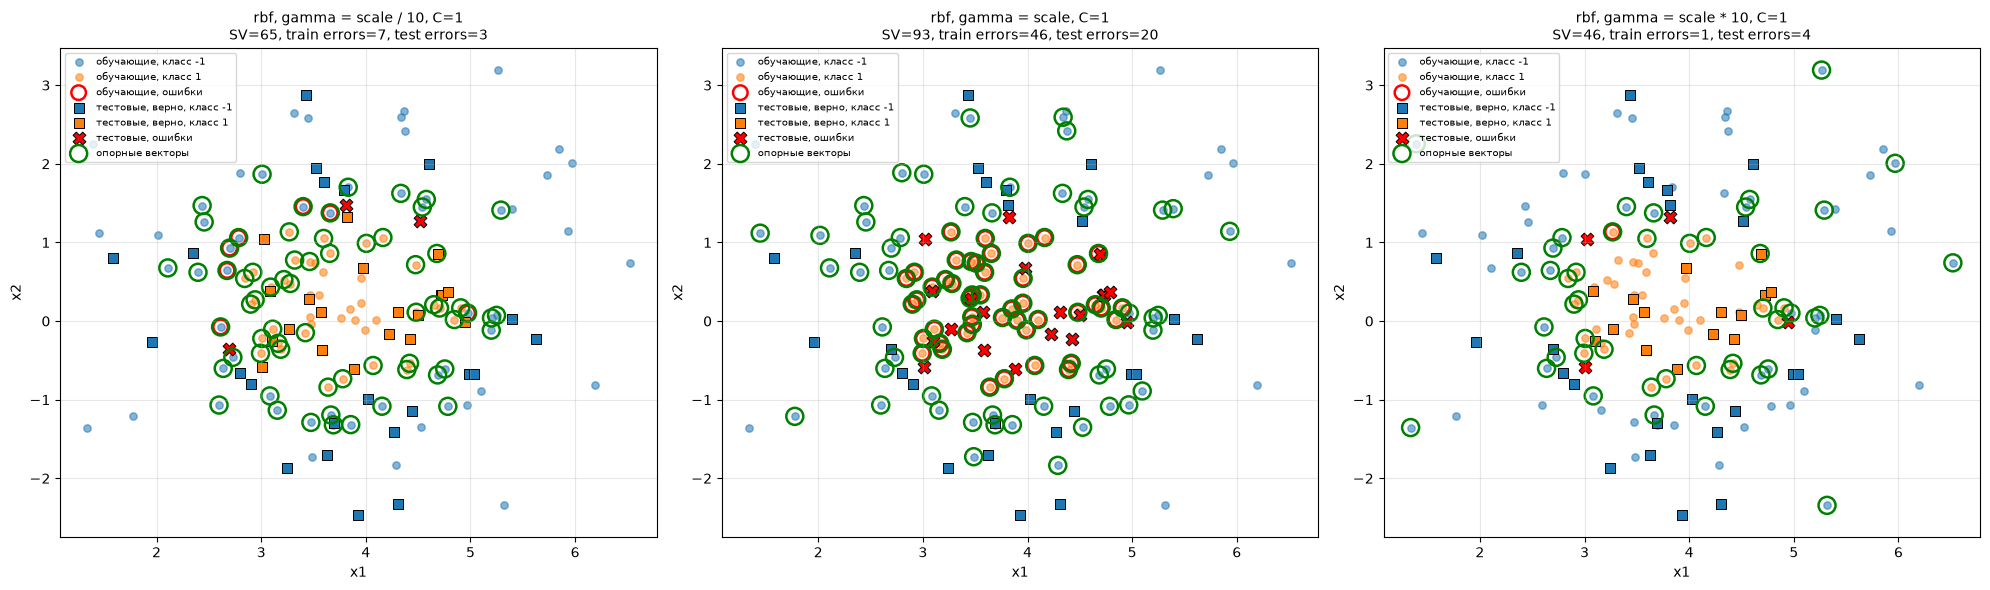

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

gamma_labels = ["gamma = scale / 10", "gamma = scale", "gamma = scale * 10"]

for ax, gamma_value, gamma_label in zip(axes, gamma_grid_1, gamma_labels):
    _, result = run_experiment(
        X1, y1,
        kernel="rbf",
        gamma_value=gamma_value,
        C=1,
        coef0=0.0,
        plot=True,
        ax=ax
    )
    ax.set_title(
        f"rbf, {gamma_label}, C=1\n"
        f"SV={result['n_support_vectors']}, "
        f"train errors={result['train_errors_total']}, "
        f"test errors={result['test_errors_total']}",
        fontsize=10
    )

plt.tight_layout()
plt.show()

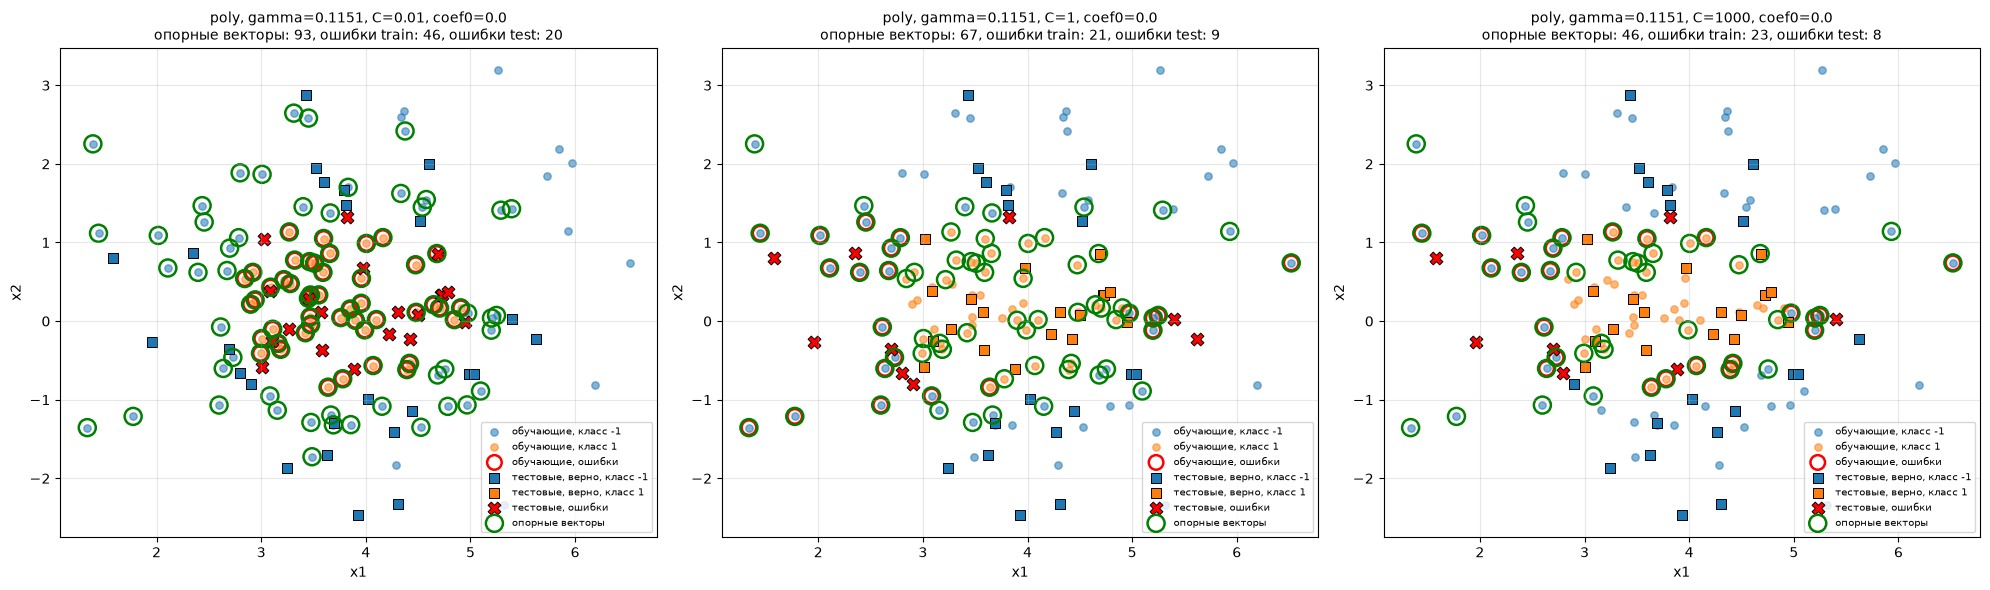

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for ax, C_value in zip(axes, [0.01, 1, 1000]):
    _, result = run_experiment(
        X1, y1,
        kernel="poly",
        gamma_value=gamma_scale_1,
        C=C_value,
        coef0=0.0,
        degree=3,
        plot=True,
        ax=ax
    )

plt.tight_layout()
plt.show()

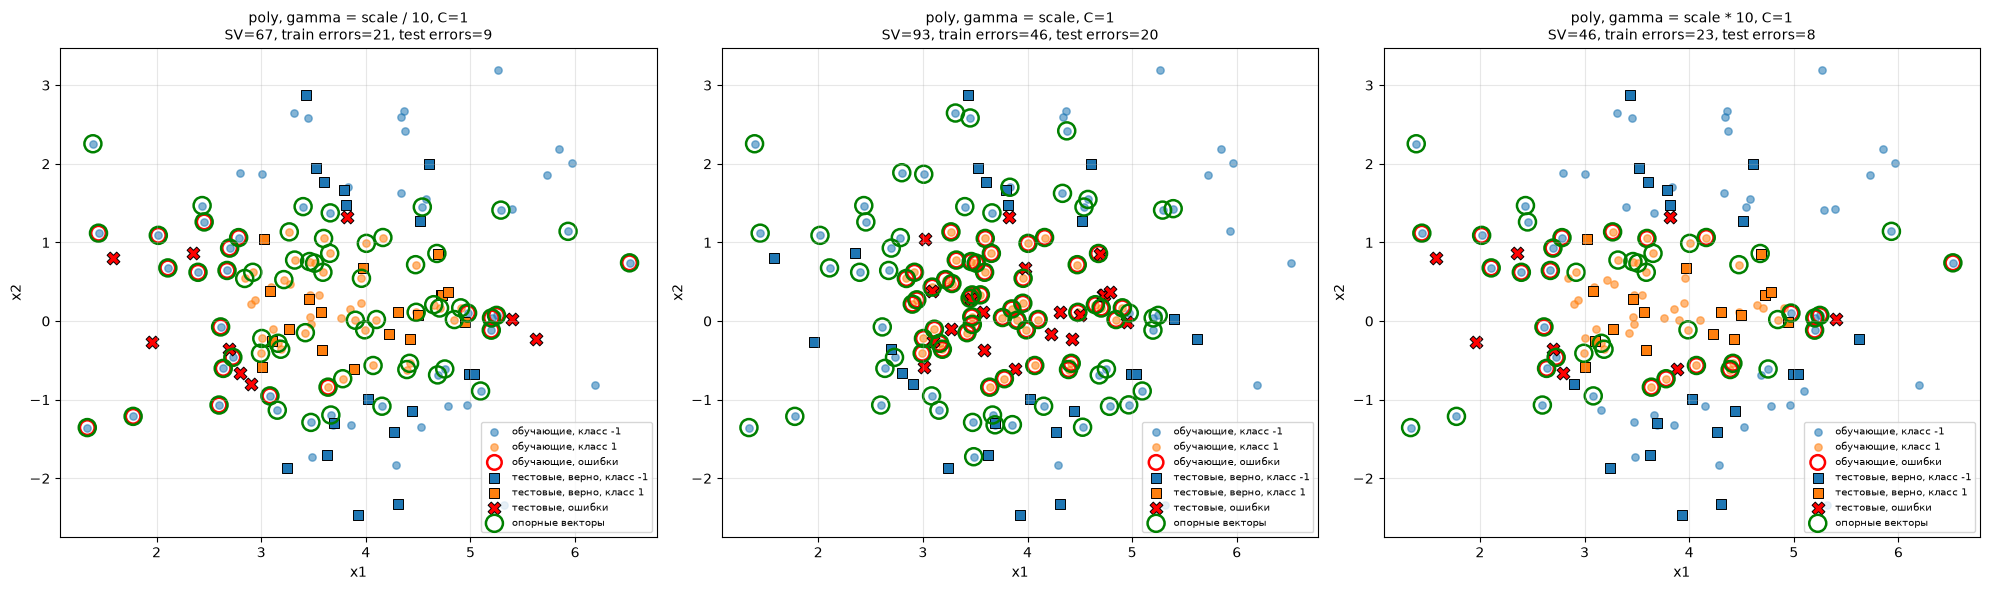

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for ax, gamma_value, gamma_label in zip(axes, gamma_grid_1, gamma_labels):
    _, result = run_experiment(
        X1, y1,
        kernel="poly",
        gamma_value=gamma_value,
        C=1,
        coef0=0.0,
        degree=3,
        plot=True,
        ax=ax
    )
    ax.set_title(
        f"poly, {gamma_label}, C=1\n"
        f"SV={result['n_support_vectors']}, "
        f"train errors={result['train_errors_total']}, "
        f"test errors={result['test_errors_total']}",
        fontsize=10
    )

plt.tight_layout()
plt.show()

In [10]:
results_1_df.sort_values(
    ["test_errors_total", "n_support_vectors"]
).head(15)

,kernel,gamma,C,coef0,degree,n_support_vectors,train_errors_total,test_errors_total,train_errors_by_class,test_errors_by_class,manual_vs_sklearn_max_abs_diff,train_errors_class_-1,test_errors_class_-1,train_errors_class_1,test_errors_class_1
5,rbf,0.011506,1000.00,0.0,3,28,1,1,"{-1: 1, 1: 0}","{-1: 0, 1: 1}",2.671641e-12,1,0,0,1
2,rbf,0.115060,1000.00,0.0,3,9,0,3,"{-1: 0, 1: 0}","{-1: 0, 1: 3}",2.415845e-13,0,0,0,3
8,rbf,1.150603,1000.00,0.0,3,16,0,3,"{-1: 0, 1: 0}","{-1: 1, 1: 2}",1.243450e-14,0,1,0,2
1,rbf,0.115060,1.00,0.0,3,65,7,3,"{-1: 7, 1: 0}","{-1: 3, 1: 0}",5.773160e-15,7,3,0,0
7,rbf,1.150603,1.00,0.0,3,46,1,4,"{-1: 0, 1: 1}","{-1: 0, 1: 4}",9.992007e-16,0,0,1,4
11,poly,0.115060,1000.00,0.0,3,46,23,8,"{-1: 15, 1: 8}","{-1: 6, 1: 2}",4.293810e-11,15,6,8,2
16,poly,1.150603,1.00,0.0,3,46,23,8,"{-1: 15, 1: 8}","{-1: 6, 1: 2}",3.728928e-11,15,6,8,2
15,poly,1.150603,0.01,0.0,3,51,23,8,"{-1: 16, 1: 7}","{-1: 6, 1: 2}",5.107026e-13,16,6,7,2
10,poly,0.115060,1.00,0.0,3,67,21,9,"{-1: 20, 1: 1}","{-1: 8, 1: 1}",8.171241e-14,20,8,1,1
14,poly,0.011506,1000.00,0.0,3,67,21,9,"{-1: 20, 1: 1}","{-1: 8, 1: 1}",8.548717e-14,20,8,1,1


In [11]:
X2, y2 = load_data("2.csv")

print("X2 shape:", X2.shape)
print("Classes:", np.unique(y2))

gamma_scale_2 = compute_gamma_scale(X2)
print("gamma scale for Nonlin_ker_2_2 =", gamma_scale_2)

gamma_grid_2 = [
    gamma_scale_2,
    gamma_scale_2 / 10,
    gamma_scale_2 * 10
]

coef0_grid = [-1.0, -0.5, 0.0, 0.5, 1.0]

gamma_grid_2, coef0_grid

X2 shape: (199, 2)
Classes: [-1  1]
gamma scale for Nonlin_ker_2_2 = 0.01463267842249278


([np.float64(0.01463267842249278),
  np.float64(0.001463267842249278),
  np.float64(0.1463267842249278)],
 [-1.0, -0.5, 0.0, 0.5, 1.0])

In [12]:
results_2 = []

for kernel in ["rbf", "poly"]:
    for gamma_value in gamma_grid_2:
        for C in [0.01, 1, 1000]:
            if kernel == "poly":
                coef0_values = coef0_grid
            else:
                coef0_values = [0.0]

            for coef0 in coef0_values:
                _, result = run_experiment(
                    X2, y2,
                    kernel=kernel,
                    gamma_value=gamma_value,
                    C=C,
                    coef0=coef0,
                    degree=3,
                    plot=False
                )
                results_2.append(result)

results_2_df = expand_error_columns(pd.DataFrame(results_2))
results_2_df

,kernel,gamma,C,coef0,degree,n_support_vectors,train_errors_total,test_errors_total,train_errors_by_class,test_errors_by_class,manual_vs_sklearn_max_abs_diff,train_errors_class_-1,test_errors_class_-1,train_errors_class_1,test_errors_class_1
0,rbf,0.014633,0.01,0.0,3,57,28,12,"{-1: 0, 1: 28}","{-1: 0, 1: 12}",2.220446e-16,0,0,28,12
1,rbf,0.014633,1.00,0.0,3,42,8,7,"{-1: 4, 1: 4}","{-1: 3, 1: 4}",9.547918e-15,4,3,4,4
2,rbf,0.014633,1000.00,0.0,3,11,0,2,"{-1: 0, 1: 0}","{-1: 0, 1: 2}",5.844214e-13,0,0,0,2
3,rbf,0.001463,0.01,0.0,3,56,28,12,"{-1: 0, 1: 28}","{-1: 0, 1: 12}",2.220446e-16,0,0,28,12
4,rbf,0.001463,1.00,0.0,3,56,28,12,"{-1: 0, 1: 28}","{-1: 0, 1: 12}",1.310063e-14,0,0,28,12
5,rbf,0.001463,1000.00,0.0,3,25,5,5,"{-1: 3, 1: 2}","{-1: 3, 1: 2}",3.268497e-12,3,3,2,2
6,rbf,0.146327,0.01,0.0,3,61,28,12,"{-1: 0, 1: 28}","{-1: 0, 1: 12}",2.220446e-16,0,0,28,12
7,rbf,0.146327,1.00,0.0,3,35,5,5,"{-1: 3, 1: 2}","{-1: 3, 1: 2}",1.332268e-15,3,3,2,2
8,rbf,0.146327,1000.00,0.0,3,19,0,4,"{-1: 0, 1: 0}","{-1: 1, 1: 3}",1.776357e-14,0,1,0,3
9,poly,0.014633,0.01,-1.0,3,57,28,12,"{-1: 0, 1: 28}","{-1: 0, 1: 12}",2.220446e-16,0,0,28,12


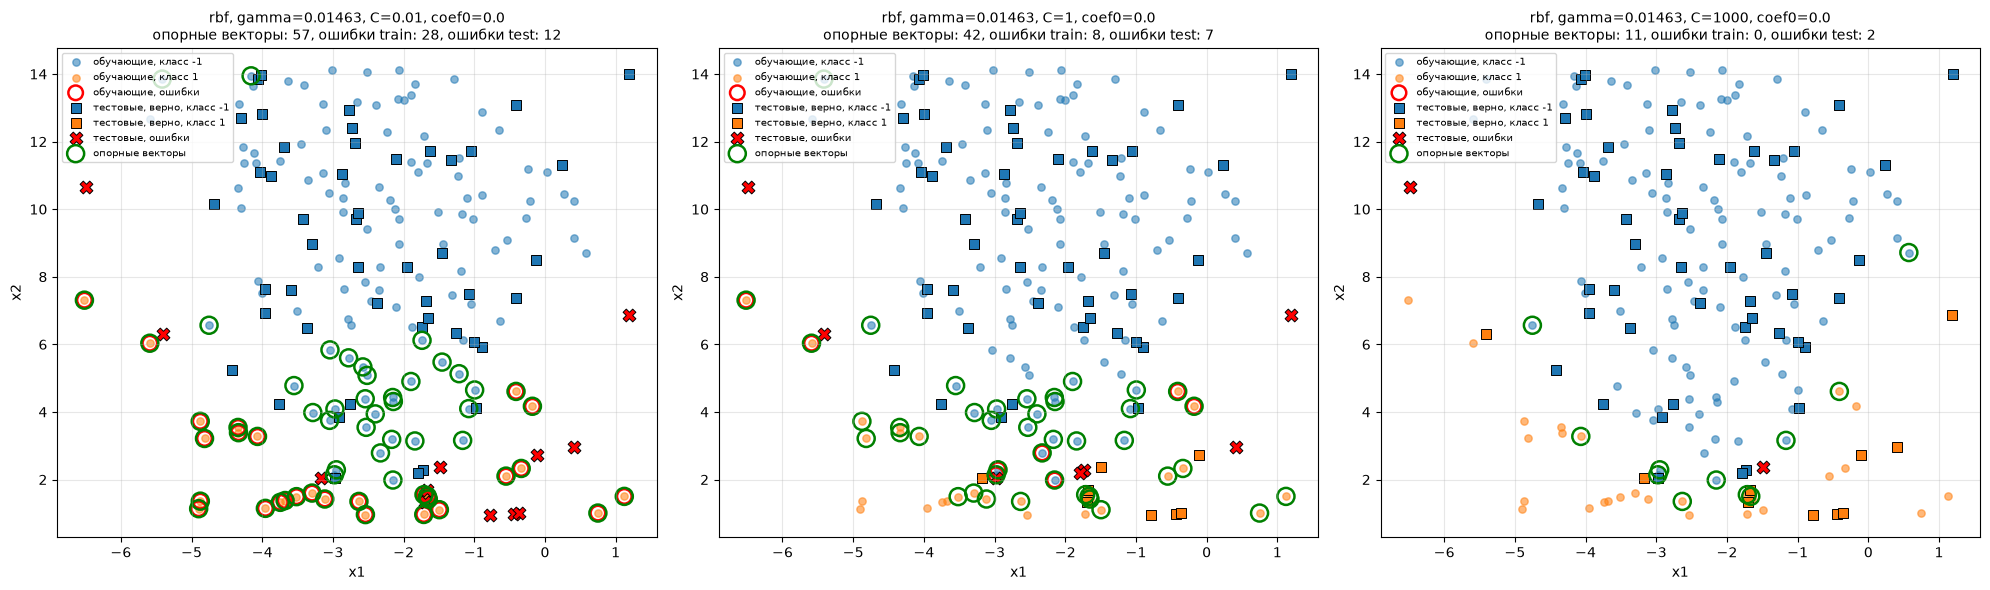

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for ax, C_value in zip(axes, [0.01, 1, 1000]):
    _, result = run_experiment(
        X2, y2,
        kernel="rbf",
        gamma_value=gamma_scale_2,
        C=C_value,
        coef0=0.0,
        plot=True,
        ax=ax
    )

plt.tight_layout()
plt.show()

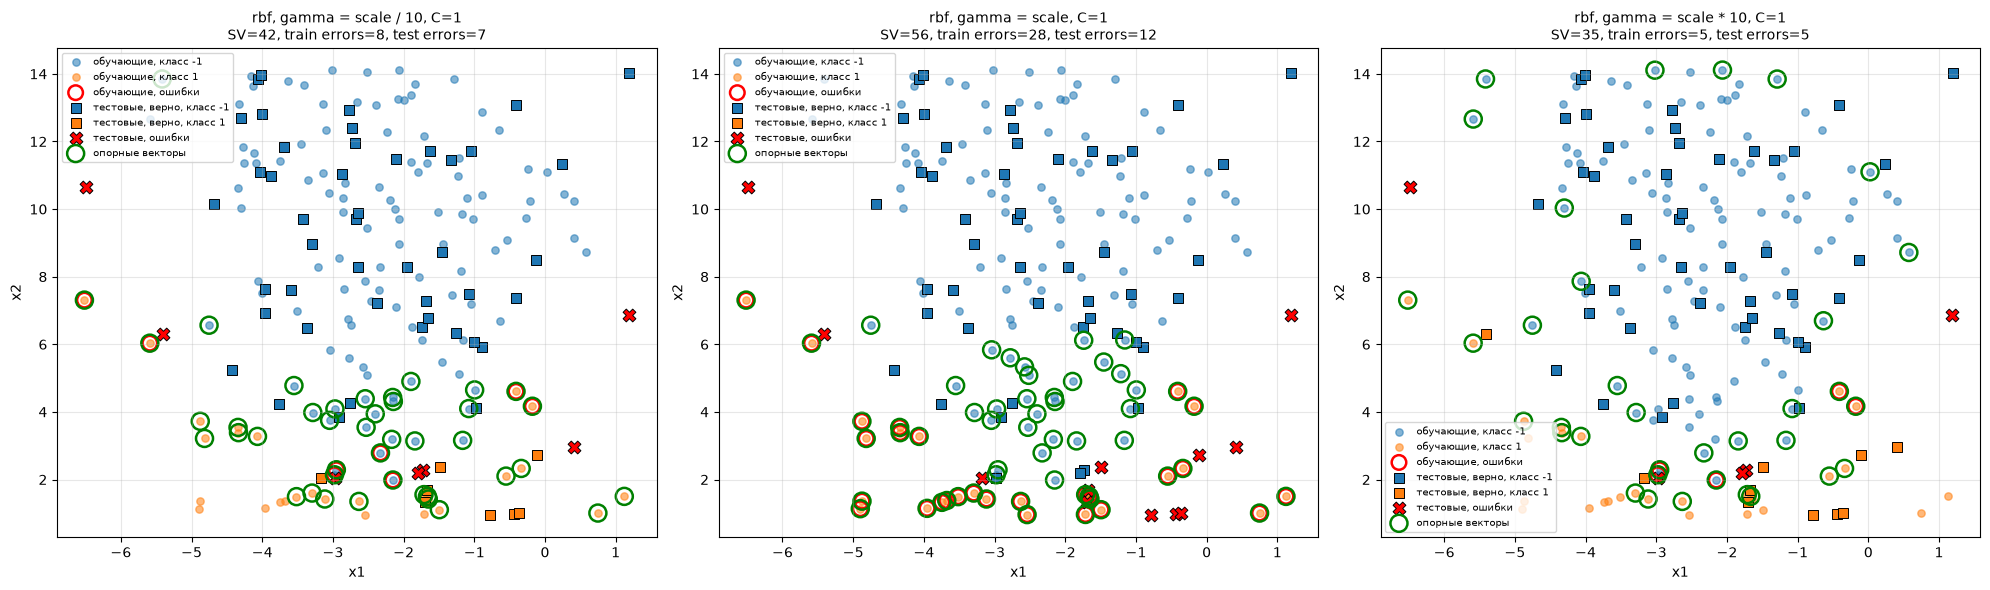

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for ax, gamma_value, gamma_label in zip(axes, gamma_grid_2, gamma_labels):
    _, result = run_experiment(
        X2, y2,
        kernel="rbf",
        gamma_value=gamma_value,
        C=1,
        coef0=0.0,
        plot=True,
        ax=ax
    )
    ax.set_title(
        f"rbf, {gamma_label}, C=1\n"
        f"SV={result['n_support_vectors']}, "
        f"train errors={result['train_errors_total']}, "
        f"test errors={result['test_errors_total']}",
        fontsize=10
    )

plt.tight_layout()
plt.show()

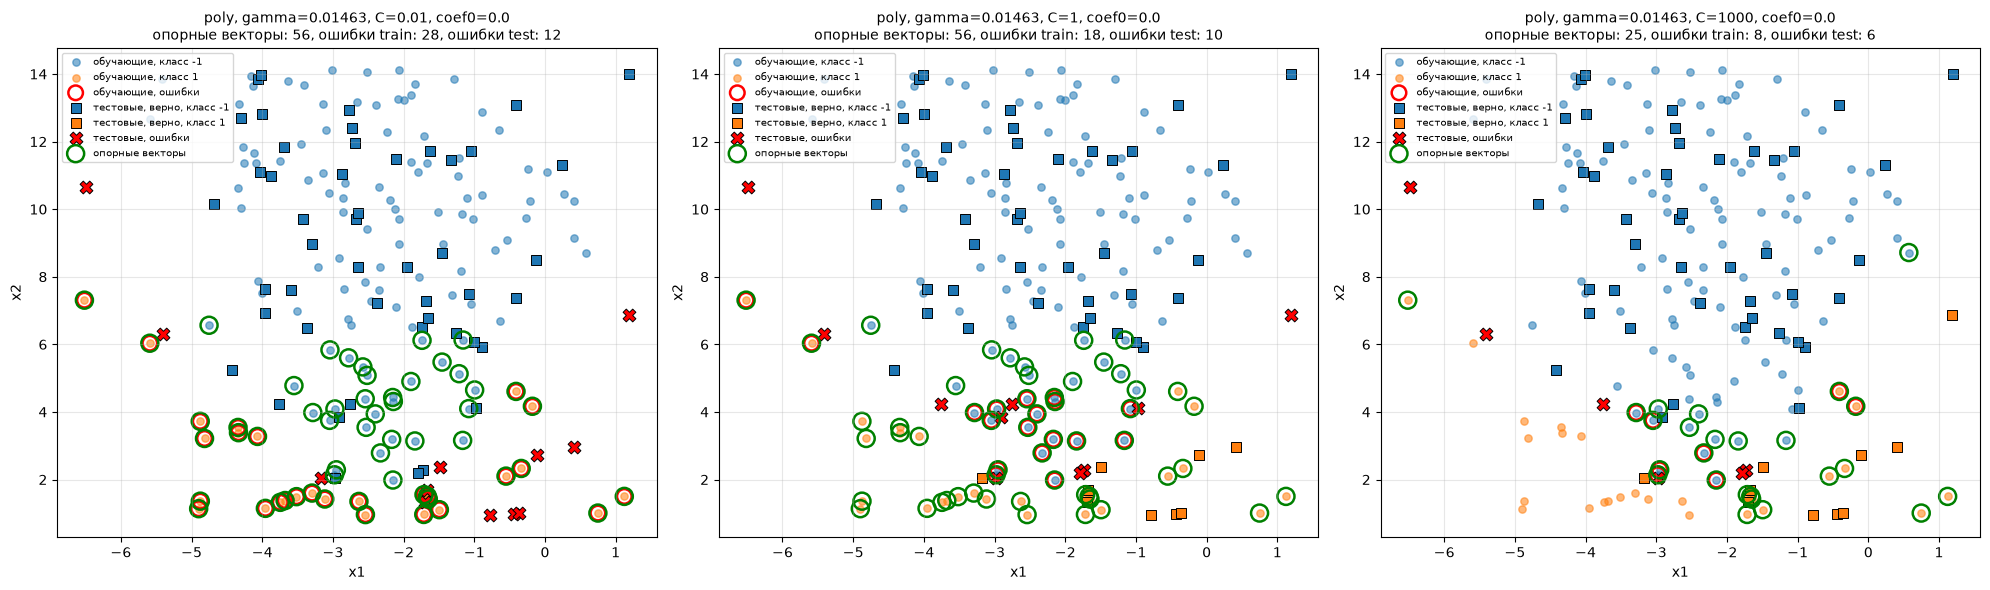

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for ax, C_value in zip(axes, [0.01, 1, 1000]):
    _, result = run_experiment(
        X2, y2,
        kernel="poly",
        gamma_value=gamma_scale_2,
        C=C_value,
        coef0=0.0,
        degree=3,
        plot=True,
        ax=ax
    )

plt.tight_layout()
plt.show()

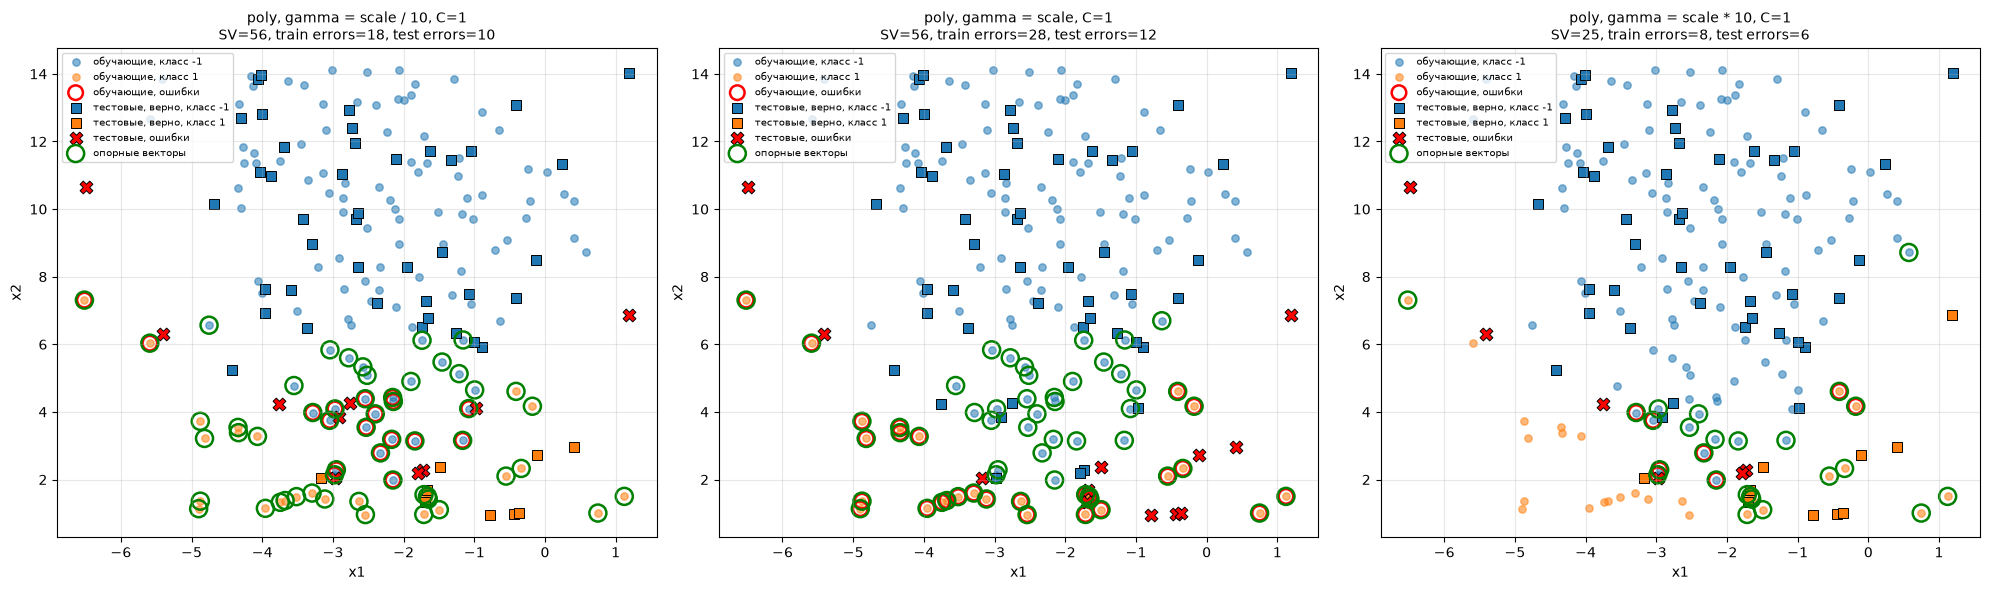

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for ax, gamma_value, gamma_label in zip(axes, gamma_grid_2, gamma_labels):
    _, result = run_experiment(
        X2, y2,
        kernel="poly",
        gamma_value=gamma_value,
        C=1,
        coef0=0.0,
        degree=3,
        plot=True,
        ax=ax
    )
    ax.set_title(
        f"poly, {gamma_label}, C=1\n"
        f"SV={result['n_support_vectors']}, "
        f"train errors={result['train_errors_total']}, "
        f"test errors={result['test_errors_total']}",
        fontsize=10
    )

plt.tight_layout()
plt.show()

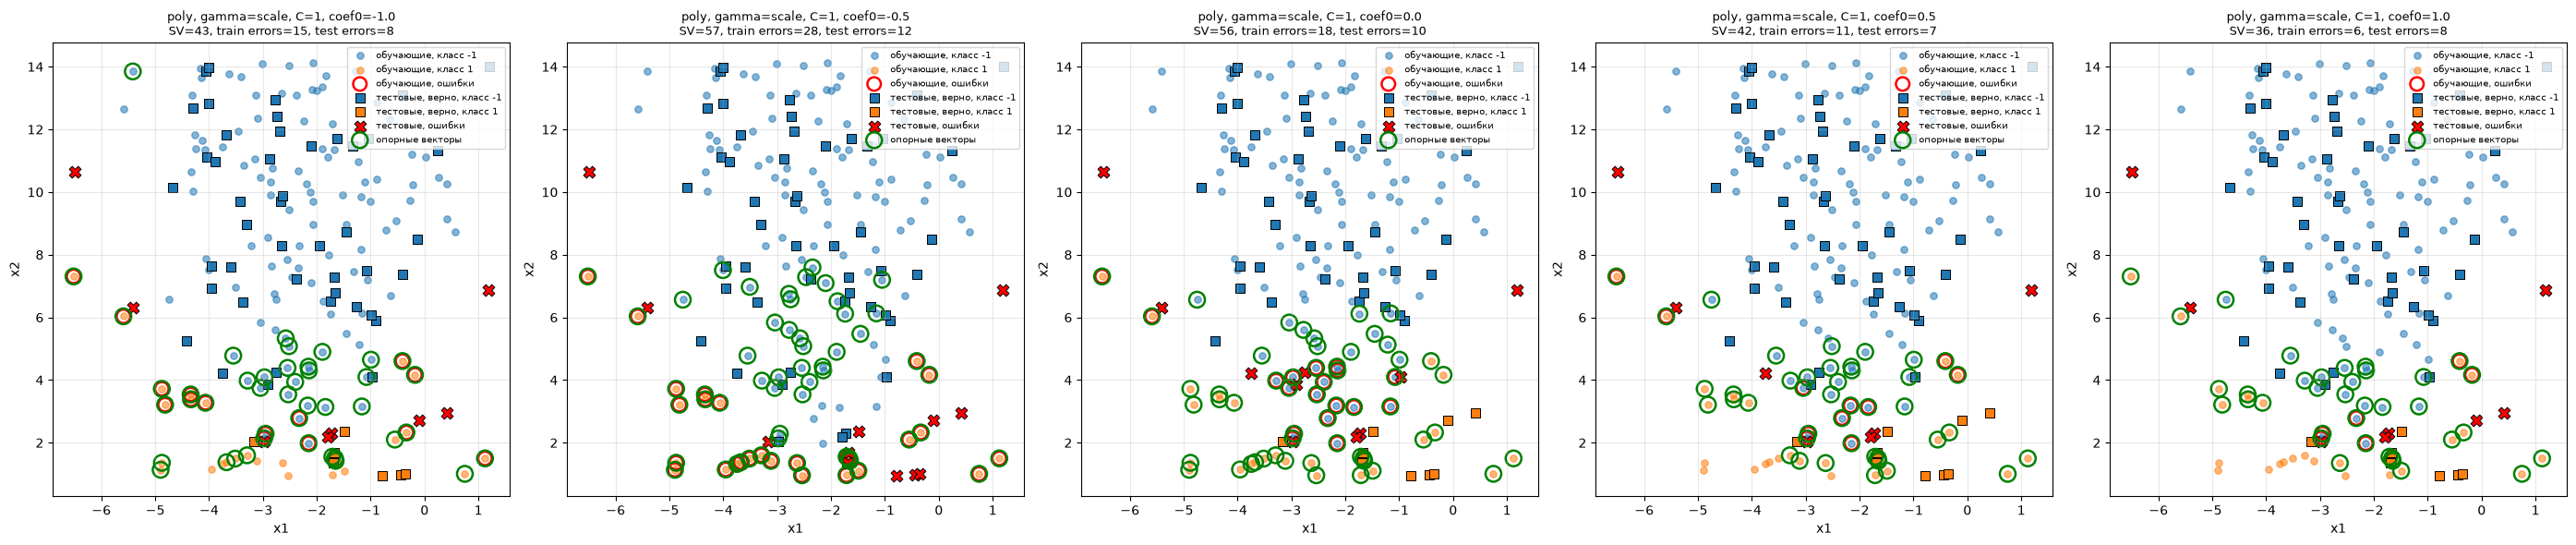

In [17]:
fig, axes = plt.subplots(1, 5, figsize=(28, 6))

for ax, coef0_value in zip(axes, coef0_grid):
    _, result = run_experiment(
        X2, y2,
        kernel="poly",
        gamma_value=gamma_scale_2,
        C=1,
        coef0=coef0_value,
        degree=3,
        plot=True,
        ax=ax
    )
    ax.set_title(
        f"poly, gamma=scale, C=1, coef0={coef0_value}\n"
        f"SV={result['n_support_vectors']}, "
        f"train errors={result['train_errors_total']}, "
        f"test errors={result['test_errors_total']}",
        fontsize=9
    )

plt.tight_layout()
plt.show()

In [18]:
X_train_2, X_test_2, y_train_2, y_test_2 = train_test_split(
    X2, y2,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y2
)

clf_check = SVC(
    kernel="poly",
    C=1,
    gamma=gamma_scale_2,
    degree=3,
    coef0=0.5,
    random_state=RANDOM_STATE
)
clf_check.fit(X_train_2, y_train_2)

for j in range(min(5, X_test_2.shape[0])):
    x_single = X_test_2[j:j + 1, :]

    manual_value = manual_decision_function(clf_check, x_single)[0]
    sklearn_value = clf_check.decision_function(x_single)[0]

    manual_class = manual_predict(clf_check, x_single)[0]
    sklearn_class = clf_check.predict(x_single)[0]

    print(f"object {j}:")
    print("  manual  decision_function =", manual_value)
    print("  sklearn decision_function =", sklearn_value)
    print("  absolute difference       =", abs(manual_value - sklearn_value))
    print("  manual predict            =", manual_class)
    print("  clf.predict               =", sklearn_class)
    print("  classes                   =", clf_check.classes_)
    print()

object 0:
  manual  decision_function = 0.7878220384816568
  sklearn decision_function = 0.7878220384816577
  absolute difference       = 8.881784197001252e-16
  manual predict            = 1
  clf.predict               = 1
  classes                   = [-1  1]

object 1:
  manual  decision_function = 0.6433911415978284
  sklearn decision_function = 0.6433911415978286
  absolute difference       = 2.220446049250313e-16
  manual predict            = 1
  clf.predict               = 1
  classes                   = [-1  1]

object 2:
  manual  decision_function = -2.1070963074970055
  sklearn decision_function = -2.1070963074970064
  absolute difference       = 8.881784197001252e-16
  manual predict            = -1
  clf.predict               = -1
  classes                   = [-1  1]

object 3:
  manual  decision_function = -7.662141943409088
  sklearn decision_function = -7.662141943409081
  absolute difference       = 7.105427357601002e-15
  manual predict            = -1
  clf.predict 

In [19]:
results_2_df.sort_values(
    ["test_errors_total", "n_support_vectors"]
).head(15)

,kernel,gamma,C,coef0,degree,n_support_vectors,train_errors_total,test_errors_total,train_errors_by_class,test_errors_by_class,manual_vs_sklearn_max_abs_diff,train_errors_class_-1,test_errors_class_-1,train_errors_class_1,test_errors_class_1
23,poly,0.014633,1000.0,1.0,3,9,0,1,"{-1: 0, 1: 0}","{-1: 0, 1: 1}",3.979039e-12,0,0,0,1
22,poly,0.014633,1000.0,0.5,3,11,0,1,"{-1: 0, 1: 0}","{-1: 0, 1: 1}",7.389644e-13,0,0,0,1
52,poly,0.146327,1000.0,0.5,3,7,0,2,"{-1: 0, 1: 0}","{-1: 0, 1: 2}",1.783462e-12,0,0,0,2
53,poly,0.146327,1000.0,1.0,3,7,0,2,"{-1: 0, 1: 0}","{-1: 0, 1: 2}",3.161915e-13,0,0,0,2
2,rbf,0.014633,1000.0,0.0,3,11,0,2,"{-1: 0, 1: 0}","{-1: 0, 1: 2}",5.844214e-13,0,0,0,2
48,poly,0.146327,1.0,1.0,3,15,3,3,"{-1: 3, 1: 0}","{-1: 3, 1: 0}",7.283063e-13,3,3,0,0
8,rbf,0.146327,1000.0,0.0,3,19,0,4,"{-1: 0, 1: 0}","{-1: 1, 1: 3}",1.776357e-14,0,1,0,3
38,poly,0.001463,1000.0,1.0,3,24,5,4,"{-1: 3, 1: 2}","{-1: 3, 1: 1}",4.616751e-12,3,3,2,1
47,poly,0.146327,1.0,0.5,3,16,4,5,"{-1: 3, 1: 1}","{-1: 3, 1: 2}",3.232969e-13,3,3,1,2
5,rbf,0.001463,1000.0,0.0,3,25,5,5,"{-1: 3, 1: 2}","{-1: 3, 1: 2}",3.268497e-12,3,3,2,2
